<a href="https://colab.research.google.com/github/yeminaung-web/machinelearning3-1/blob/main/simpleRNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install finance-datareader
import FinanceDataReader as fdr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [finance-datareader]


In [2]:
samsung = fdr.DataReader('005930', '2016')
print(samsung)

              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  195400  187000  194300  10437247  0.004134

[2660 rows x 6 columns]


In [3]:
openValues = [[samsung]]

In [4]:
target_column = samsung['Open'].values.reshape(-1, 1)

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))
scaled = scaler.fit_transform(target_column)


In [5]:
TEST_SIZE = 200
train_data = scaled[:-TEST_SIZE]
test_data = scaled[-TEST_SIZE:]

In [6]:
def make_sample(data, window):
  train = []
  target = []
  for i in range(len(data) - window):
    train.append(data[i:i+window])
    target.append(data[i+window])
  return np.array(train), np.array(target)
X_train, y_train = make_sample(train_data, 30)
X_test, y_test = make_sample(test_data, 30)

In [7]:
!pip install tensorflow

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import SimpleRNN

model = Sequential()
model.add(SimpleRNN(16, input_shape=(X_train.shape[1], 1),
               activation='tanh',
               return_sequences=False))
model.add(Dense(1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [9]:
model.compile(optimizer = 'adam', loss = 'mean_squared_error')
model.fit(X_train, y_train, epochs = 30, batch_size = 16)

Epoch 1/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - loss: 5.7584e-04
Epoch 2/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 5.6209e-05
Epoch 3/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 4.9519e-05
Epoch 4/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.5657e-05
Epoch 5/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.5539e-05
Epoch 6/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.5159e-05
Epoch 7/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.3576e-05
Epoch 8/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.1463e-05
Epoch 9/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.6957e-05
Epoch 10/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.9439e-05
Epoch 11/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.3104e-05
Epoch 12/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.1202e-05
Epoch 13/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.3603e-05
Epoch 14/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.8410e-05


In [10]:
X_test, y_test = make_sample(test_data, 30)
pred = model.predict(X_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step


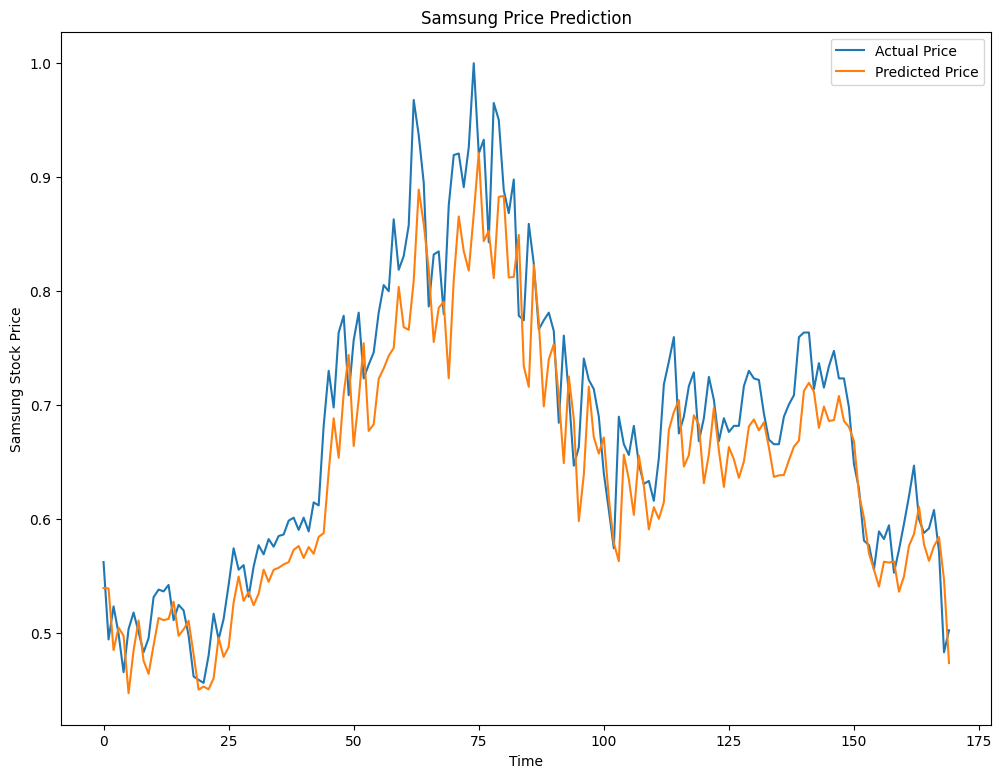

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 9))
plt.plot(y_test, label='Actual Price')
plt.plot(pred, label='Predicted Price')
plt.title('Samsung Price Prediction')
plt.xlabel('Time')
plt.ylabel('Samsung Stock Price')
plt.legend()
plt.show()